In [34]:
import os
import sys
sys.path.insert(0, "../../Python/cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time
import pickle

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [35]:
t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
# t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1

In [36]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/../../Python/model_data/parameters.csv')

for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [37]:
initial_concentrations = pd.read_csv(os.getcwd() + '/../../Python/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [38]:
integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

In [39]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run() #deterministic simulation

In [40]:
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A

<Axes: xlabel='Time (h)', ylabel='Concentration'>

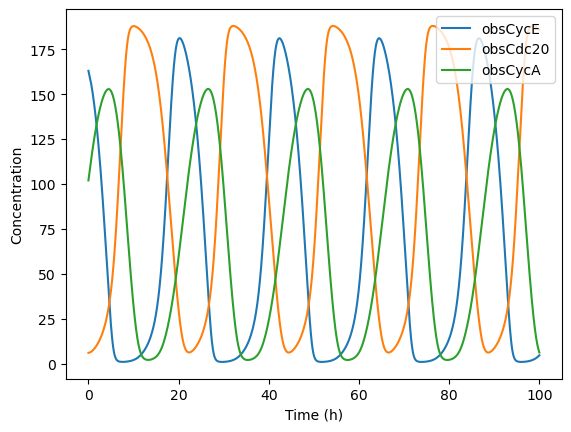

In [41]:

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,100000), legend=True)


In [ ]:

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,100000), legend=True)


In [42]:
from scipy.signal import find_peaks

In [43]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)

In [44]:
AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100

In [45]:
AKTt=[0.3,0.6]
ERKt=[0.2,0.2]
FAKt=[0.4,0.6]

In [46]:
integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

In [47]:
VERBOSE=True

In [48]:
POINTS=5

In [22]:
def run_lyaps(AKT, ERK, FAK, np=np, model=model, points=POINTS, ScipyOdeSimulator=ScipyOdeSimulator,
              find_peaks=find_peaks, integrator_options=integrator_options, norm=norm, math=math,
              verbose=VERBOSE):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    ep = 0.001 * 200
    t = np.linspace(0, 1000, 1000001)
    t_0 = np.linspace(0, 2000, 2000001)
    all_logz = dict.fromkeys(list(range(1, points + 1)))

    for kk in range(points):
        sim_ode = ScipyOdeSimulator(model, t_0, verbose=False, compiler='python',
                                    integrator_options=integrator_options).run()
        y_out = sim_ode.observables

        peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence=0.6, distance=10)
        # new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
        peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
        peaks_half2 = peaks_cdc[peaks_cdc > len(y_out) / 2]

        if len(peaks_half2) > 3:
            IMTs = [t_0[y] - t_0[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
            meanIMT = sum(IMTs) / len(IMTs)
            variable_range = y_out[peaks_half[-3]:peaks_half[-2]]
            tmp_loc = (round(len(variable_range) / (points)) * (kk))
        else:
            meanIMT = 0
            variable_range = y_out[575000:600000]
            tmp_loc = (round(len(variable_range) / (points)) * (kk))
        if verbose:
            print(meanIMT)


        Initial_1 = variable_range[tmp_loc]
        Initial_1 = [val + ep for val in Initial_1]

        prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
                 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
                 'Cdc20_0']
        prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}

        for key in prot_init.keys():
            model.parameters[key].value = prot_init[key] / model.parameters['omega'].value

        sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                                     integrator_options=integrator_options).run()
        y_out1 = sim_ode1.observables

        z = [0] * (round((len(y_out1) / 2000)) + 1)
        n = 0
        for i in range(0, len(y_out1), 2000):
            if len(peaks_half2) > 0:
                window = y_out[peaks_half[-3]+i+tmp_loc-5000:peaks_half[-2]+i+tmp_loc+5000]
            else:
                window = y_out[575000+i+tmp_loc-5000:600000+i+tmp_loc+5000]

            dists = [0] * len(window)
            for j in range(0, len(window)):
                dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
                dists[j] = norm(dif[0:19]/200)

            z[n] = min(dists)
            n = n + 1

        logz = [math.log(num) for num in z]
        all_logz[kk + 1] = logz
        if verbose:
            print([AKT, ERK, FAK, kk])

    return all_logz, meanIMT

In [17]:
start = time.time()
all_logz, meanIMT = run_lyaps(0, 0, 0)
end = time.time()
print(end - start)

0
[0, 0, 0, 0]
0
[0, 0, 0, 1]
407.84018087387085


In [151]:
def run_lyaps_point(AKT, ERK, FAK, np=np, model=model, ScipyOdeSimulator=ScipyOdeSimulator,
              find_peaks=find_peaks, integrator_options=integrator_options, norm=norm, math=math,
              verbose=VERBOSE):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    ep = 0.001 * 200
    t = np.linspace(0, 1000, 1000001)
    t_0 = np.linspace(0, 2000, 2000001)
    # all_logz = dict.fromkeys(list(range(1, points + 1)))
    
    
    sim_ode = ScipyOdeSimulator(model, t_0, verbose=False, compiler='python',
                                integrator_options=integrator_options).run()
    y_out = sim_ode.observables

    meanIMT = 0
    Initial_0 = y_out[-1]
    Initial_1 = [val + ep for val in Initial_0]
    
    prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
             'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
             'Cdc20_0']
    prot_init_0 = {prots[i]: Initial_0[i] for i in range(len(prots))}
    prot_init_1 = {prots[i]: Initial_1[i] for i in range(len(prots))}

    for key in prot_init_0.keys():
        model.parameters[key].value = prot_init_0[key] / model.parameters['omega'].value
    sim_ode0 = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                                 integrator_options=integrator_options).run()
    y_out0 = sim_ode0.observables

    for key in prot_init_1.keys():
        model.parameters[key].value = prot_init_1[key] / model.parameters['omega'].value
    sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                                 integrator_options=integrator_options).run()
    y_out1 = sim_ode1.observables

    z = [0] * (round((len(y_out1) / 2000)) + 1)
    n = 0   
    for i in range(0, len(y_out1), 2000):
        dif = np.asarray(y_out0[i].tolist())-np.asarray(y_out1[i].tolist())
        z[n] = norm(dif[0:19]/200)
        n = n + 1

    logz = [math.log(num) for num in z]

    if verbose:
        print([AKT, ERK, FAK])

    return logz, meanIMT

In [23]:
start = time.time()
with mp.Pool(processes = 6) as p:
    results = p.starmap(run_lyaps, [(0, 0, 0),
                                    (0.20909090909090908, 0.1393939393939394, 0.2787878787878788)])
end = time.time()
print(end - start)

4527.125247001648


In [25]:
z_list = [num[0] for num in results]
mean_IMT = [num[1] for num in results]
mean_IMT


z_list = [num[0] for num in results]
mean_IMT = [num[1] for num in results]

df = pd.DataFrame(z_list)
mean_df = pd.DataFrame(mean_IMT)

cycdi = str(round(model.parameters['CycDi_0'].value % 1,2)).split('.')[1]

In [28]:
SET_JPARAM = False

filename_l = str(Path(SAVE_DIR, f'lyaps_ERL_cycdi_0_0_low.fea')) # feather might have an issue with Path object

filename_IMT = str(Path(SAVE_DIR, f'mINT_ERL_cycdi_0_0_low.fea'))


In [32]:
import pyarrow.feather as feather

In [33]:
print(f'Saving file to {filename_l}...')
feather.write_feather(mean_df, filename_IMT)
feather.write_feather(df, filename_l)

Saving file to C:\Users\olesk\ECM_mod_output\lyaps_ERL_cycdi_0_0_low.fea...


In [24]:
z_list = [num[0] for num in results]
mean_IMT = [num[1] for num in results]
mean_IMT

[0, 119.09042857142857]

In [152]:
# AKT=0
# ERK=0
# FAK=0

AKT=0.1484848484848485
ERK=0.09898989898989899
FAK=0.19797979797979798

In [153]:
logz, meanIMT = run_lyaps_point(AKT, ERK, FAK)

[0.1484848484848485, 0.09898989898989899, 0.19797979797979798]


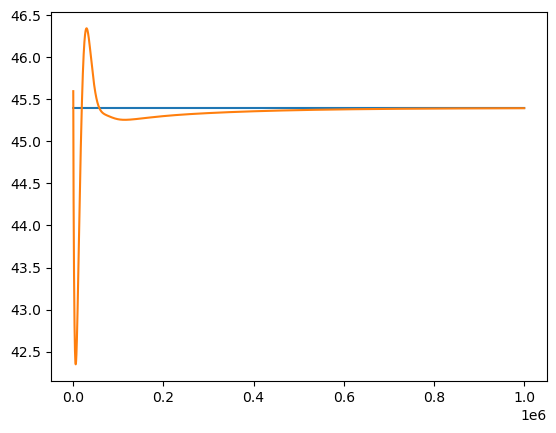

In [145]:
plt.plot(y_out0['obsp21'])
plt.plot(y_out1['obsp21'])

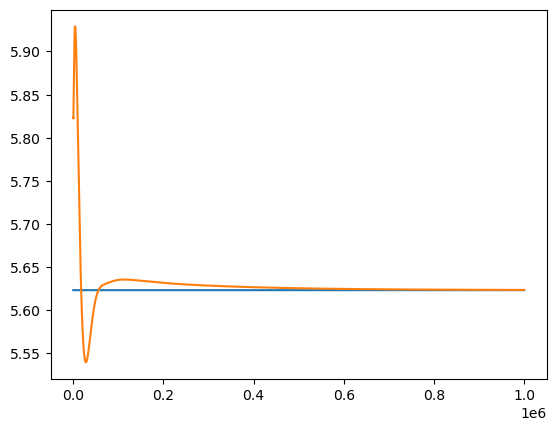

In [155]:
plt.plot(y_out0['obsCycE'])
plt.plot(y_out1['obsCycE'])

In [146]:
logz = [math.log(num) for num in z]

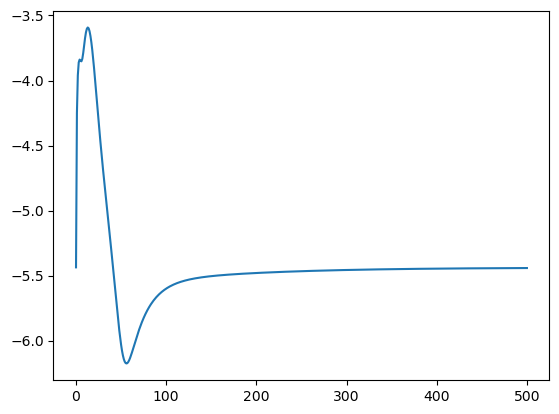

In [147]:
plt.plot(logz)

In [148]:
def fit_lyap(lyap_trace):
    t = np.linspace(0, 1000, 501)
    max_t=np.argmax(lyap_trace)
    #np.argmin(results[1][1][tmp:])
    min_t = min(lyap_trace[max_t:])
    min_r = math.ceil(min_t*10)/10
    min_inds = [i for i,v in enumerate(lyap_trace) if v <= min_r]
    if min_inds[0] > max_t:
        coef = np.polyfit(t[max_t:min_inds[0]],lyap_trace[max_t:min_inds[0]],1)
        poly1d_fn = np.poly1d(coef)   
    else:
        coef = np.polyfit(t,lyap_trace,1)
        poly1d_fn = np.poly1d(coef)   
    return coef[0]

In [149]:
fit_lyap(logz)

-0.0349955261399929

In [95]:
lyap_trace = logz

In [103]:
t = np.linspace(0, 1000, 501)
max_t=np.argmax(lyap_trace)
min_t = min(lyap_trace[max_t:])
min_r = math.ceil(min_t*10)/10
min_inds = [i for i,v in enumerate(lyap_trace) if v <= min_r]
coef = np.polyfit(t[max_t:],lyap_trace[max_t:],1)
poly1d_fn = np.poly1d(coef)  

In [104]:
coef[0]

-0.00012514876211553244

In [ ]:
tmp=np.argmax(results[1][1])
np.argmin(results[1][1][tmp:])
test = min(results[1][1][tmp:])
math.ceil(test*10)/10

In [ ]:
plt.plot(all_logz[1])

In [ ]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results = p.starmap(run_lyaps, [(AKT, ERK, FAK) for AKT in AKTt for ERK in ERKt for FAK in FAKt])
end = time.time()
print(end - start)

In [ ]:
len(all_logz)

In [44]:
def func(a, b):
    c = a + b
    d = 1
    return c, d

In [45]:
a_args = [1,2,3]
second_arg = 1
with mp.Pool() as pool:
    L = pool.starmap(func, [(1, 1), (2, 1), (3, 1)])

In [46]:
L

[(2, 1), (3, 1), (4, 1)]

In [19]:
points = 1
kk = 0

In [13]:
model.parameters['AKT'].value = AKTs[0]
model.parameters['ERK'].value = ERKs[0]
model.parameters['FAK'].value = FAKs[0]

In [16]:
sim_ode = ScipyOdeSimulator(model, t_0, verbose=False, compiler='python', integrator_options=integrator_options).run()
y_out = sim_ode.observables

In [17]:
ep = 0.001*200


In [28]:
peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)
peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
peaks_half2 = peaks_cdc[peaks_cdc > len(y_out)/2]

if len(peaks_half2) > 0:
    IMTs = [t_0[y] - t_0[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
    meanIMT = sum(IMTs) / len(IMTs)
else:
    meanIMT = 0

variable_range=y_out[peaks_half[-2]:peaks_half[-1]]
tmp_loc = (round(len(variable_range)/(points))*(kk))



In [29]:
meanIMT

22.437534883720932

In [ ]:
len(variable_range)

In [ ]:
kk=1
tmp_loc = (round(len(variable_range)/kk)*(kk-1))


In [ ]:
Initial_1 = new_y[tmp_loc]
Initial_1

In [ ]:
Initial_1 = [val+ep for val in Initial_1]
new_y_ab = new_y[tmp_loc:]

In [ ]:
Initial_1

In [ ]:
# prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
#  'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
#  'Cdc20_0', 'BAX_0', 'BAXmBCL2_0', 'BH3_0', 'BH3BCL2_0', 'BAXm_0', 'BCL2_0']
# prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
# #del prot_init['BAXm_0']
# #del prot_init['BCL2_0']

In [ ]:
prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
 'Cdc20_0']
prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
#del prot_init['BAXm_0']
#del prot_init['BCL2_0']

In [ ]:
model.parameters['Cdc20_0'].value

In [ ]:
for key in prot_init.keys():
    model.parameters[key].value = prot_init[key] / model.parameters['omega'].value

In [ ]:
model.parameters['Cdc20_0'].value

In [ ]:
t = np.linspace(0, 1000, 1000001)
#t = np.linspace(0, 10, 10001)

In [ ]:
sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
y_out1 = sim_ode1.observables


In [ ]:
plt.plot(variable_range['obsCdc20'][0:1200]/200)
plt.plot(y_out1['obsCdc20'][0:1200]/200)

In [ ]:
len(y_out1)

In [ ]:
i = 0
j = 0
dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
norm(dif)

In [ ]:
dists = [0]*len(variable_range)
for j in range(0, len(variable_range)):
    dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
    dists[j] = norm(dif)

In [ ]:
plt.plot(dists)

In [ ]:
min(dists)

In [ ]:
z=[0]*(round((len(y_out1)/2000))+1)
n=0

In [ ]:
for i in range(0, len(y_out1), 2000):
    dists = [0]*len(variable_range)
    for j in range(0, len(variable_range)):
        dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
        dists[j] = norm(dif)
    
    z[n] = min(dists)
    n=n+1
    if n%100 == 0:
        print(n)

In [ ]:
tmp = [num+0.0001 for num in z]

In [ ]:
logz = [math.log(num) for num in z]
plt.plot(logz)

In [ ]:
z